### What are Embeddings
Think of embeddings as a way to translate words into a language that computer understand - numbers!

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Simplified 2D examples (real embeddings have hundreds of dimensions)

word_embeddings={
    "cat":[0.8,0.6],
    "kitten":[0.75,0.65],
    "dog":[0.7,0.3],
    "puppy":[0.65,0.35],
    "car":[-0.5,0.2],
    "truck":[-0.45,0.15]
}

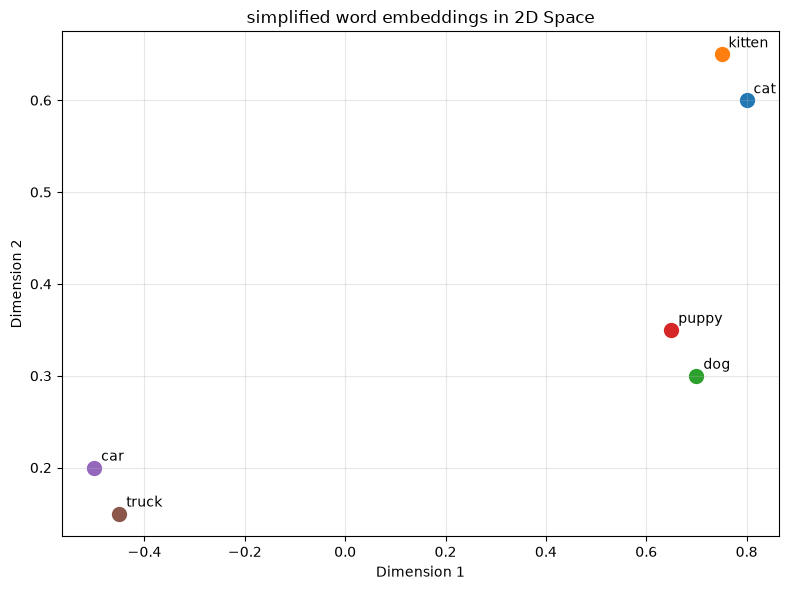

In [ ]:
fig,ax =plt.subplots(figsize=(8,6))

for word,coords in word_embeddings.items():
    ax.scatter(coords[0],coords[1], s=100)
    ax.annotate(word,(coords[0],coords[1]),xytext=(5,5),textcoords='offset points')
ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_title('simplified word embeddings in 2D Space')
ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()


# Measuring Similarity – Cosine Similarity

**Cosine Similarity** measures the angle between two vectors to determine how similar their directions are.

## Interpretation of Cosine Similarity

- **Result close to 1:** Very similar direction.
- **Result close to 0:** Little or no directional similarity.
- **Result close to -1:** Opposite directions.

## Formula

\[
\text{Cosine Similarity} = \frac{A \cdot B}{\|A\|\|B\|}
\]

Where:
- `A` and `B` are two vectors.
- `A · B` is the dot product of the vectors.
- `||A||` and `||B||` are the magnitudes (lengths) of the vectors.

**Note:** In NLP and text embeddings, cosine similarity is commonly used to measure semantic similarity between words, sentences, or documents. A score close to 1 generally indicates similar meaning, although the exact interpretation depends on the embedding model.

In [ ]:
import numpy as np
def consine_similarity(vec1,vec2):
    dot_product=np.dot(vec1,vec2)
    norm_a=np.linalg.norm(vec1)
    norm_b=np.linalg.norm(vec2)
    return(dot_product/norm_a*norm_b)

In [ ]:
## Examples

cat_vector = [0.8,0.6,0.3]
kitten_vector = [0.75,0.65,0.35]
car_vector = [-0.5,0.2,0.1]

cat_kitten_similarity = consine_similarity(cat_vector,kitten_vector)
print(cat_kitten_similarity) #1.1037551365117844

1.1037551365117844


In [ ]:
car_kitten_similarity=consine_similarity(cat_vector,car_vector)
print(car_kitten_similarity) # -0.13115576564675044

-0.13115576564675044


## Creating your First Embeddings

In [ ]:
### Hugging Face embedding 

from langchain_huggingface import HuggingFaceEmbeddings

# Initialize a Hugging Face embedding model (no API key required)

#https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4970.41it/s]


In [4]:
## Create your First Embeddings

text="Hello, I am learning about embeddings!"

embedding=embeddings.embed_query(text)
print(f"Text:{text}")
print(f"Embedding length: {len(embedding)}")
print(f"{embedding}")

Text:Hello, I am learning about embeddings!
Embedding length: 384
[-0.01816326379776001, -0.09955169260501862, 0.013816027902066708, -0.00812597293406725, 0.01415228471159935, 0.0640648677945137, -0.006253377068787813, -0.003017888404428959, 0.025287209078669548, -0.02019863948225975, 0.02432972751557827, 0.07435064017772675, 0.05117722973227501, 0.02203851193189621, -0.05830617621541023, 0.01526821218430996, 0.023584362119436264, 0.09455390274524689, -0.06508845090866089, 0.013296646066009998, -0.020497558638453484, -0.05690857768058777, 0.03030332177877426, -0.08365609496831894, 0.026596298441290855, -0.015231452882289886, -0.04361540079116821, 0.05398401618003845, 0.09025716781616211, -0.08893883973360062, 0.03964461758732796, -0.008835024200379848, -0.03034374490380287, 0.07425564527511597, -0.0540991947054863, 0.11107997596263885, 0.036899879574775696, -0.008959847502410412, -0.06140241026878357, -0.0031433829572051764, 0.021958177909255028, 0.04220819100737572, -0.028937866911292

In [10]:
## Embeddings for Multiple line

sentences=[
    "The cat sat on the mat",
    "A feline rested on the rug",
    "The dog played in the yard",
    "I love programming in python",
    "Python is my favourite programming language"
]

embedding_sentences=embeddings.embed_documents(sentences)
print(embedding_sentences) #[[],[]]
print(len(embedding_sentences))
print(embedding_sentences[0])


[[0.1304018348455429, -0.011870143935084343, -0.028117045760154724, 0.05123864859342575, -0.055974461138248444, 0.03019157610833645, 0.0301612988114357, 0.02469835989177227, -0.018370550125837326, 0.058766789734363556, -0.02495318092405796, 0.06015429645776749, 0.039831750094890594, 0.03323053941130638, -0.06131138652563095, -0.049373120069503784, -0.054863523691892624, -0.04007606953382492, 0.05642912536859512, 0.03915657103061676, -0.03473709896206856, -0.013247691094875336, 0.031966231763362885, -0.06349925696849823, -0.06017860025167465, 0.0782344862818718, -0.028303857892751694, -0.047442834824323654, 0.040359266102313995, -0.006630869582295418, -0.06674093753099442, -0.004191359039396048, -0.02531164139509201, 0.053341638296842575, 0.017428111284971237, -0.09792359918355942, 0.006061280146241188, -0.06524161994457245, 0.04557257890701294, 0.023641828447580338, 0.0765848457813263, -0.010264387354254723, -0.004076810088008642, -0.062322843819856644, 0.033705271780490875, 0.01866113

In [11]:
from langchain_huggingface import HuggingFaceEmbeddings
import time

# Popular models comparison
models = {
    "all-MiniLM-L6-v2": {
        "size": 384,
        "description": "Fast and efficient, good quality",
        "use_case": "General purpose, real-time applications"
    },
    "all-mpnet-base-v2": {
        "size": 768,
        "description": "Best quality, slower than MiniLM",
        "use_case": "When quality matters more than speed"
    },
    "all-MiniLM-L12-v2": {
        "size": 384,
        "description": "Slightly better than L6, bit slower",
        "use_case": "Good balance of speed and quality"
    },
    "multi-qa-MiniLM-L6-cos-v1": {
        "size": 384,
        "description": "Optimized for question-answering",
        "use_case": "Q&A systems, semantic search"
    },
    "paraphrase-multilingual-MiniLM-L12-v2": {
        "size": 384,
        "description": "Supports 50+ languages",
        "use_case": "Multilingual applications"
    }
}

print("📊 Popular Open Source Embedding Models:\n")
for model_name, info in models.items():
    print(f"Model: sentence-transformers/{model_name}")
    print(f"  📏 Embedding size: {info['size']} dimensions")
    print(f"  📝 Description: {info['description']}")
    print(f"  🎯 Use case: {info['use_case']}\n")


📊 Popular Open Source Embedding Models:

Model: sentence-transformers/all-MiniLM-L6-v2
  📏 Embedding size: 384 dimensions
  📝 Description: Fast and efficient, good quality
  🎯 Use case: General purpose, real-time applications

Model: sentence-transformers/all-mpnet-base-v2
  📏 Embedding size: 768 dimensions
  📝 Description: Best quality, slower than MiniLM
  🎯 Use case: When quality matters more than speed

Model: sentence-transformers/all-MiniLM-L12-v2
  📏 Embedding size: 384 dimensions
  📝 Description: Slightly better than L6, bit slower
  🎯 Use case: Good balance of speed and quality

Model: sentence-transformers/multi-qa-MiniLM-L6-cos-v1
  📏 Embedding size: 384 dimensions
  📝 Description: Optimized for question-answering
  🎯 Use case: Q&A systems, semantic search

Model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
  📏 Embedding size: 384 dimensions
  📝 Description: Supports 50+ languages
  🎯 Use case: Multilingual applications

